# Experiment 4 — BM25F stemming analysis
Comparison of stemming vs no stemming, with stopword removal disabled, retrieval depth 100, top-10 ranking and Discounted CombSUM. Metrics are based on incomplete known-positive judgments.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path('bm25_stemming_results')  # notebook located in testing/
OUT = DATA_DIR / 'plots'
OUT.mkdir(parents=True, exist_ok=True)
summary = pd.read_csv(DATA_DIR / 'summary.csv')
metrics = pd.read_csv(DATA_DIR / 'metrics.csv')
comparison = pd.read_csv(DATA_DIR / 'comparison.csv')
rankings = pd.read_csv(DATA_DIR / 'rankings.csv')
print(summary.to_string(index=False))

    variant    query_type  queries  known_recall_at_k  known_mrr_at_k  known_ndcg_at_k
no_stemming      academic      226           0.526917        0.346948         0.376198
no_stemming       overall      452           0.443768        0.279016         0.306037
no_stemming student_style      226           0.360619        0.211083         0.235876
   stemming      academic      226           0.546091        0.332027         0.370284
   stemming       overall      452           0.445133        0.281262         0.309501
   stemming student_style      226           0.344174        0.230498         0.248717


## 1. Overall metrics

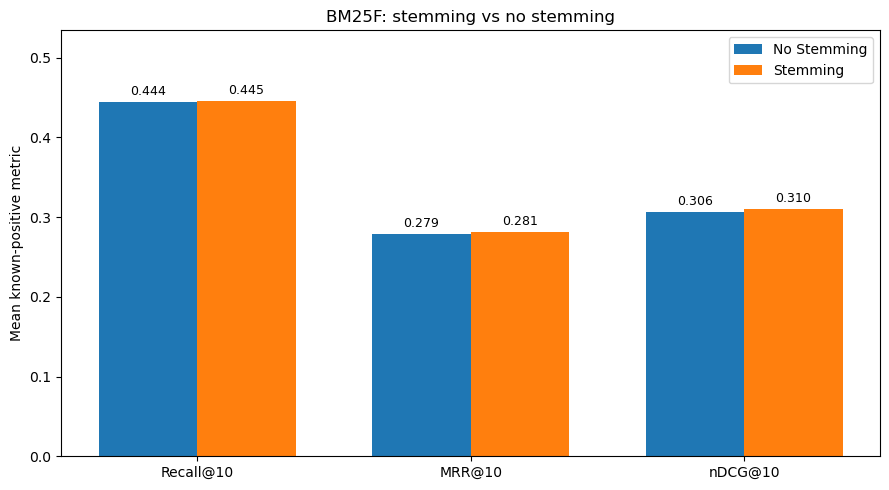

In [2]:
names = {'known_recall_at_k':'Recall@10', 'known_mrr_at_k':'MRR@10', 'known_ndcg_at_k':'nDCG@10'}
overall = summary[summary.query_type.eq('overall')].set_index('variant')
x = np.arange(3)
fig, ax = plt.subplots(figsize=(9,5))
for i, variant in enumerate(['no_stemming','stemming']):
    vals = overall.loc[variant, list(names)]
    bars = ax.bar(x + (i-.5)*.36, vals, width=.36, label=variant.replace('_',' ').title())
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xticks(x, list(names.values()))
ax.set_ylim(0, max(overall[list(names)].to_numpy().ravel())*1.2)
ax.set_ylabel('Mean known-positive metric')
ax.set_title('BM25F: stemming vs no stemming')
ax.legend()
fig.tight_layout(); fig.savefig(OUT/'01_overall_metrics.png',dpi=180); plt.show()

## 2. nDCG by query type

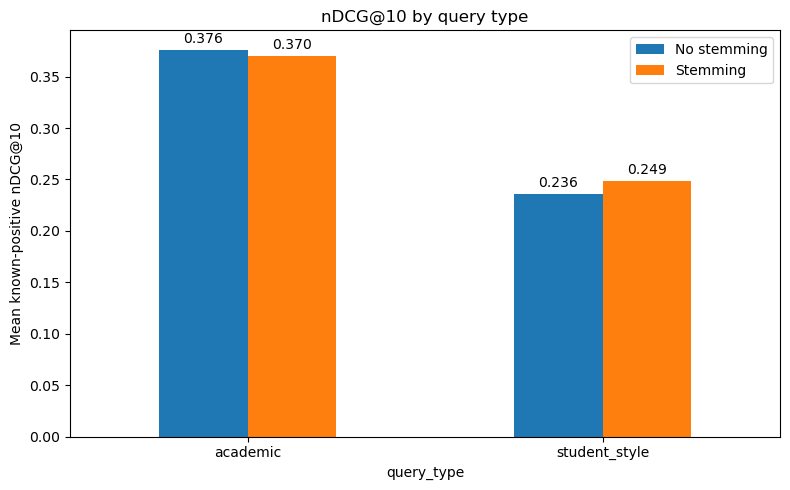

In [3]:
subset = summary[summary.query_type.isin(['academic','student_style'])]
pivot = subset.pivot(index='query_type',columns='variant',values='known_ndcg_at_k').loc[['academic','student_style']]
ax = pivot[['no_stemming','stemming']].plot.bar(figsize=(8,5),rot=0)
ax.set_title('nDCG@10 by query type')
ax.set_ylabel('Mean known-positive nDCG@10')
ax.legend(['No stemming','Stemming'])
for container in ax.containers: ax.bar_label(container,fmt='%.3f',padding=3)
plt.tight_layout();plt.savefig(OUT/'02_ndcg_by_query_type.png',dpi=180);plt.show()

## 3. Paired per-query nDCG differences

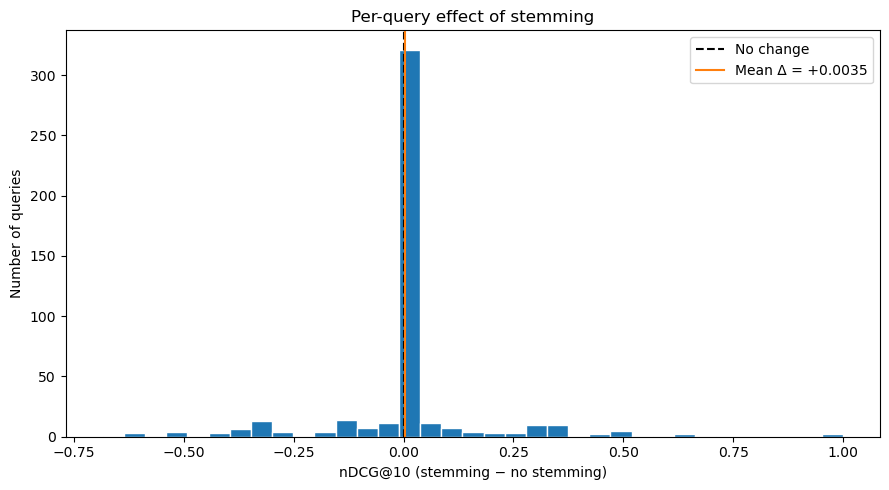

Improved: 67 Worsened: 70 Unchanged: 315


In [4]:
wide = metrics.pivot(index='query_id',columns='variant',values='known_ndcg_at_k')
meta = metrics.drop_duplicates('query_id').set_index('query_id')[['query','query_type']]
paired = meta.join(wide)
paired['delta'] = paired['stemming'] - paired['no_stemming']
fig,ax=plt.subplots(figsize=(9,5))
ax.hist(paired['delta'],bins=35,edgecolor='white')
ax.axvline(0,color='black',linestyle='--',label='No change')
ax.axvline(paired['delta'].mean(),color='tab:orange',linestyle='-',label=f"Mean Δ = {paired['delta'].mean():+.4f}")
ax.set(xlabel='nDCG@10 (stemming − no stemming)',ylabel='Number of queries',title='Per-query effect of stemming')
ax.legend();fig.tight_layout();fig.savefig(OUT/'03_ndcg_delta_distribution.png',dpi=180);plt.show()
print('Improved:',(paired.delta>1e-12).sum(),'Worsened:',(paired.delta< -1e-12).sum(),'Unchanged:',(paired.delta.abs()<=1e-12).sum())

## 4. Query-type differences in stemming effect

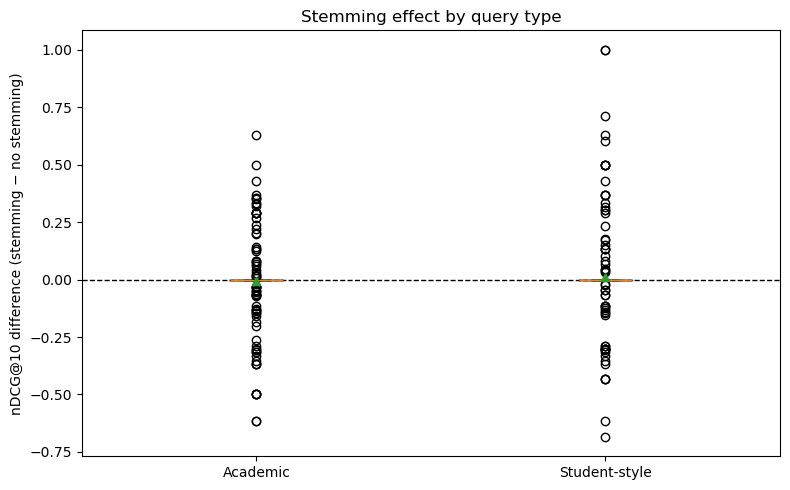

In [5]:
data=[paired.loc[paired.query_type.eq(t),'delta'] for t in ['academic','student_style']]
fig,ax=plt.subplots(figsize=(8,5))
ax.boxplot(data,tick_labels=['Academic','Student-style'],showmeans=True)
ax.axhline(0,color='black',linestyle='--',linewidth=1)
ax.set(ylabel='nDCG@10 difference (stemming − no stemming)',title='Stemming effect by query type')
fig.tight_layout();fig.savefig(OUT/'04_delta_by_query_type.png',dpi=180);plt.show()

## 5. Ranking stability

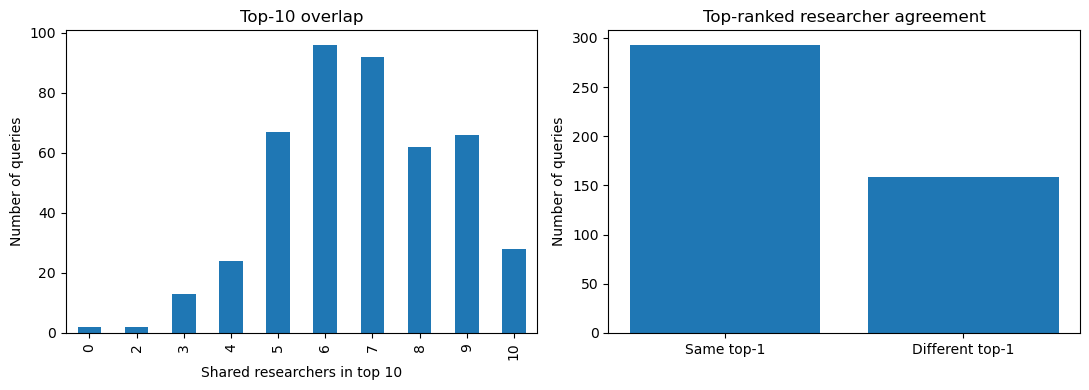

Average top-10 overlap: 6.78
Same top-1 fraction: 0.648


In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
comparison.top_k_overlap.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(xlabel='Shared researchers in top 10',ylabel='Number of queries',title='Top-10 overlap')
axes[1].bar(['Same top-1','Different top-1'],[(comparison.same_top_1==1).sum(),(comparison.same_top_1==0).sum()])
axes[1].set(ylabel='Number of queries',title='Top-ranked researcher agreement')
fig.tight_layout();fig.savefig(OUT/'05_ranking_stability.png',dpi=180);plt.show()
print('Average top-10 overlap:',round(comparison.top_k_overlap.mean(),2))
print('Same top-1 fraction:',round(comparison.same_top_1.mean(),3))

## 6. Examples of queries helped or hurt by stemming

In [7]:
cols=['query_type','query','no_stemming','stemming','delta']
print('Most improved queries:')
display(paired.sort_values('delta',ascending=False)[cols].head(10))
print('Most worsened queries:')
display(paired.sort_values('delta')[cols].head(10))

Most improved queries:


,query_type,query,no_stemming,stemming,delta
query_id,,,,,
266,student_style,How could I use or study law human in a univer...,0.000000,1.00000,1.000000
206,student_style,How could I use or study city planners in a un...,0.000000,1.00000,1.000000
430,student_style,How could I use or study politics facebook in ...,0.289065,1.00000,0.710935
22,student_style,What would happen if hackers attacked critical...,0.000000,0.63093,0.630930
293,academic,Training program and european commission,0.000000,0.63093,0.630930
322,student_style,How could I use or study refugee camps in a un...,0.397809,1.00000,0.602191
23,academic,payment system resilience,0.000000,0.50000,0.500000
392,student_style,How could I use or study case management in a ...,0.500000,1.00000,0.500000
378,student_style,How could I use or study case management in a ...,0.500000,1.00000,0.500000


Most worsened queries:


,query_type,query,no_stemming,stemming,delta
query_id,,,,,
140,student_style,How could I use or study big things in a unive...,1.000000,0.315465,-0.684535
100,student_style,How could I use or study red teaming in a univ...,0.797723,0.184576,-0.613147
105,academic,Query optimisation and tech summit,1.000000,0.386853,-0.613147
195,academic,Social cultural and humanities social,0.613147,0.000000,-0.613147
49,academic,evolutionary algorithms and AI,1.000000,0.500000,-0.500000
441,academic,Called deep and computer programs,1.000000,0.500000,-0.500000
177,academic,Complexity theory and erc starting,0.500000,0.000000,-0.500000
163,academic,Center computing and computing education,1.000000,0.500000,-0.500000
244,student_style,How could I use or study image analysis in a u...,0.430677,0.000000,-0.430677


## Interpretation notes

- Overall known-positive nDCG@10 changes only slightly (0.3060 → 0.3095).
- Academic nDCG@10 decreases (0.3762 → 0.3703), while student-style nDCG@10 increases (0.2359 → 0.2487).
- Stemming therefore appears more helpful for conversational queries, but the effect is mixed and relatively small.
- Review per-query gains and losses before selecting stemming as a default.
- Because relevance labels are incomplete and some queries are related, these findings should be treated as preliminary rather than definitive.

Stemming produced small improvements across all overall evaluation metrics, with the largest benefit observed in student-style nDCG@10. However, performance varied by query type, with a slight decrease in academic nDCG@10. Based on these results, stemming was provisionally selected for further experimentation, while the non-stemming configuration was retained as a baseline. Further evaluation is required to determine whether the observed improvements are robust.